# Imports and definitions

In [1]:
# imports
from numpy import cos, sin, arctan, sqrt, exp
from kuibit.simdir import SimDir
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
# display dynamical plots
%matplotlib widget

In [3]:
# calls Carpet2ygraphCat.pl to write a 1D quantity from ASCII to plain text, with the format
# ```
#  # time = xxx
#  coord value
#  (...)
# ```
# returns a dictionary with the list of `coord` and `value` for all instants of time
# if there are more than one `output-XXXX`, it appends to the previous timesteps
# if there are overlapping time steps, then the higher output is considered
def GetMesh(sd, quantity, axis):
    coords = {}
    data = {}

    for N in [s.replace("output-", "") for s in os.popen(f"ls {sd.path}").read().split()[1:]]:
        path = f"{sd.path}/output-{N}/{quantity}.{axis}.asc"
        xgpath = f"{sd.path}/output-{N}/{quantity}.{axis}.xg"

        if not os.path.isfile(xgpath):
            os.popen(f"perl /home/undercover/projects/cactus/repos/carpet/CarpetIOASCII/src/util/Carpet2ygraphCat.pl {path}")
            os.wait()

        file = open(xgpath, "r")
        file_str = file.read()

        for block in file_str.split("\n\n#")[1:]:
            block = block.split("\n")

            time = block[0].split()[-1]

            N = len(block[1:-1])
            coords[f"t={time}"] = np.empty(N)
            data[f"t={time}"]   = np.empty(N)

            i = 0
            for line in block[1:-1]:
                line = line.split()
                coords[f"t={time}"][i] = float(line[0])
                data[f"t={time}"][i]   = float(line[1])

                i += 1

        file.close()

    return coords, data

# Fetch data

In [4]:
sd = SimDir("../simulations/NRID_BSSN_L=504_k=1_t=0.5,0.25_alpha-minus=-0.5pi_x0=10_QuasiCircular_NoSpin_h=6")
sd_highres = SimDir("../simulations/NRID_BSSN_L=504_k=1_t=0.5,0.25_alpha-minus=-0.5pi_x0=10_QuasiCircular_NoSpin_h=4")
sd_bc = SimDir("../simulations/NRID_BSSN_L=504_k=1_t=0.5,0.25_alpha-minus=-0.5pi_x0=10_QuasiCircular_NoSpin_BC-Coulomb_h=6")
sd_bc_highres = SimDir("../simulations/NRID_BSSN_L=504_k=1_t=0.5,0.25_alpha-minus=-0.5pi_x0=10_QuasiCircular_NoSpin_BC-Coulomb_h=4")

# Punctures

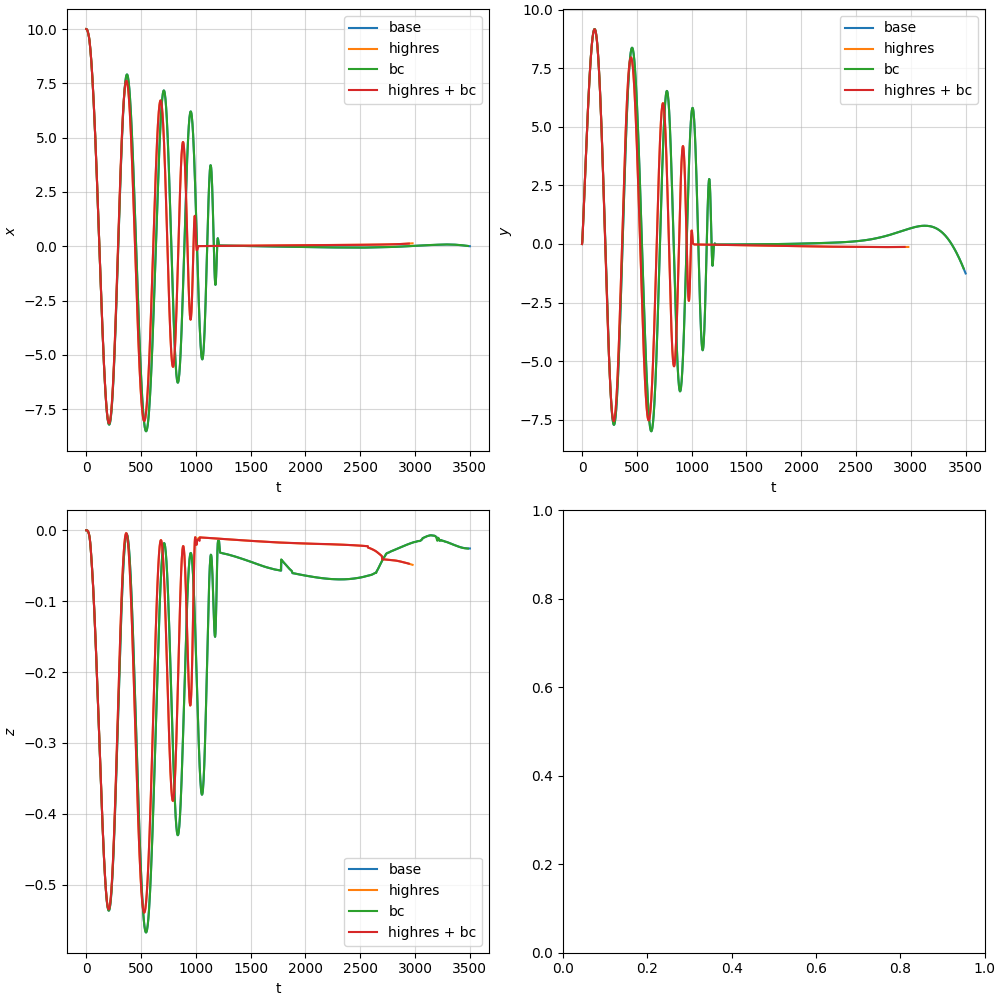

In [49]:
fig, ax = plt.subplots(2, 2, figsize=(10,10), constrained_layout=True)

hor  = sd.horizons
hor1 = hor.get_apparent_horizon(1)
hor2 = hor.get_apparent_horizon(2)
hor_highres  = sd_highres.horizons
hor1_highres = hor_highres.get_apparent_horizon(1)
hor2_highres = hor_highres.get_apparent_horizon(2)
hor_bc  = sd_bc.horizons
hor1_bc = hor_bc.get_apparent_horizon(1)
hor2_bc = hor_bc.get_apparent_horizon(2)
hor_bc_highres  = sd_bc_highres.horizons
hor1_bc_highres = hor_bc_highres.get_apparent_horizon(1)
hor2_bc_highres = hor_bc_highres.get_apparent_horizon(2)

ax[0,0].plot(hor1.get_ah_property("centroid_x").t,            hor1.get_ah_property("centroid_x").y.real,            label="base")
ax[0,0].plot(hor1_highres.get_ah_property("centroid_x").t,    hor1_highres.get_ah_property("centroid_x").y.real,    label="highres")
ax[0,0].plot(hor1_bc.get_ah_property("centroid_x").t,         hor1_bc.get_ah_property("centroid_x").y.real,         label="bc")
ax[0,0].plot(hor1_bc_highres.get_ah_property("centroid_x").t, hor1_bc_highres.get_ah_property("centroid_x").y.real, label="highres + bc")

ax[0,0].grid(alpha=0.5)
ax[0,0].set_xlabel("t")
ax[0,0].set_ylabel(r"$x$")
ax[0,0].legend()

ax[0,1].plot(hor1.get_ah_property("centroid_y").t,            hor1.get_ah_property("centroid_y").y.real,            label="base")
ax[0,1].plot(hor1_highres.get_ah_property("centroid_y").t,    hor1_highres.get_ah_property("centroid_y").y.real,    label="highres")
ax[0,1].plot(hor1_bc.get_ah_property("centroid_y").t,         hor1_bc.get_ah_property("centroid_y").y.real,         label="bc")
ax[0,1].plot(hor1_bc_highres.get_ah_property("centroid_y").t, hor1_bc_highres.get_ah_property("centroid_y").y.real, label="highres + bc")

ax[0,1].grid(alpha=0.5)
ax[0,1].set_xlabel("t")
ax[0,1].set_ylabel(r"$y$")
ax[0,1].legend();

ax[1,0].plot(hor1.get_ah_property("centroid_z").t,            hor1.get_ah_property("centroid_z").y.real,            label="base")
ax[1,0].plot(hor1_highres.get_ah_property("centroid_z").t,    hor1_highres.get_ah_property("centroid_z").y.real,    label="highres")
ax[1,0].plot(hor1_bc.get_ah_property("centroid_z").t,         hor1_bc.get_ah_property("centroid_z").y.real,         label="bc")
ax[1,0].plot(hor1_bc_highres.get_ah_property("centroid_z").t, hor1_bc_highres.get_ah_property("centroid_z").y.real, label="highres + bc")

ax[1,0].grid(alpha=0.5)
ax[1,0].set_xlabel("t")
ax[1,0].set_ylabel(r"$z$")
ax[1,0].legend();

# Far-away scalar quantities

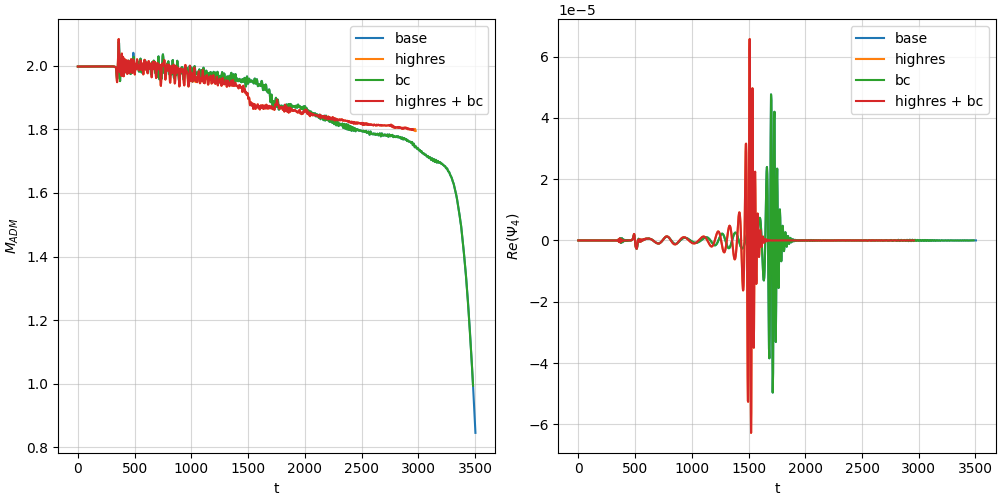

In [37]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(10,5), constrained_layout=True)

R = 480
mode = (2,2)

ax1.plot(sd.horizons[5,6].adm_energy.t,            sd.horizons[5,6].adm_energy.y,            label="base")
ax1.plot(sd_highres.horizons[5,6].adm_energy.t,    sd_highres.horizons[5,6].adm_energy.y,    label="highres")
ax1.plot(sd_bc.horizons[5,6].adm_energy.t,         sd_bc.horizons[5,6].adm_energy.y,         label="bc")
ax1.plot(sd_bc_highres.horizons[5,6].adm_energy.t, sd_bc_highres.horizons[5,6].adm_energy.y, label="highres + bc")

ax1.grid(alpha=0.5)
ax1.set_xlabel(r"t")
ax1.set_ylabel(r"$M_{ADM}$")
ax1.legend()

ax2.plot(sd.multipoles["Psi4"][R][mode].t,            sd.multipoles["Psi4"][R][mode].y.real,            label="base")
ax2.plot(sd_highres.multipoles["Psi4"][R][mode].t,    sd_highres.multipoles["Psi4"][R][mode].y.real,    label="highres")
ax2.plot(sd_bc.multipoles["Psi4"][R][mode].t,         sd_bc.multipoles["Psi4"][R][mode].y.real,         label="bc")
ax2.plot(sd_bc_highres.multipoles["Psi4"][R][mode].t, sd_bc_highres.multipoles["Psi4"][R][mode].y.real, label="highres + bc")

ax2.grid(alpha=0.5)
ax2.set_xlabel(r"t")
ax2.set_ylabel(r"$Re \left( \Psi_4 \right)$")
ax2.legend();

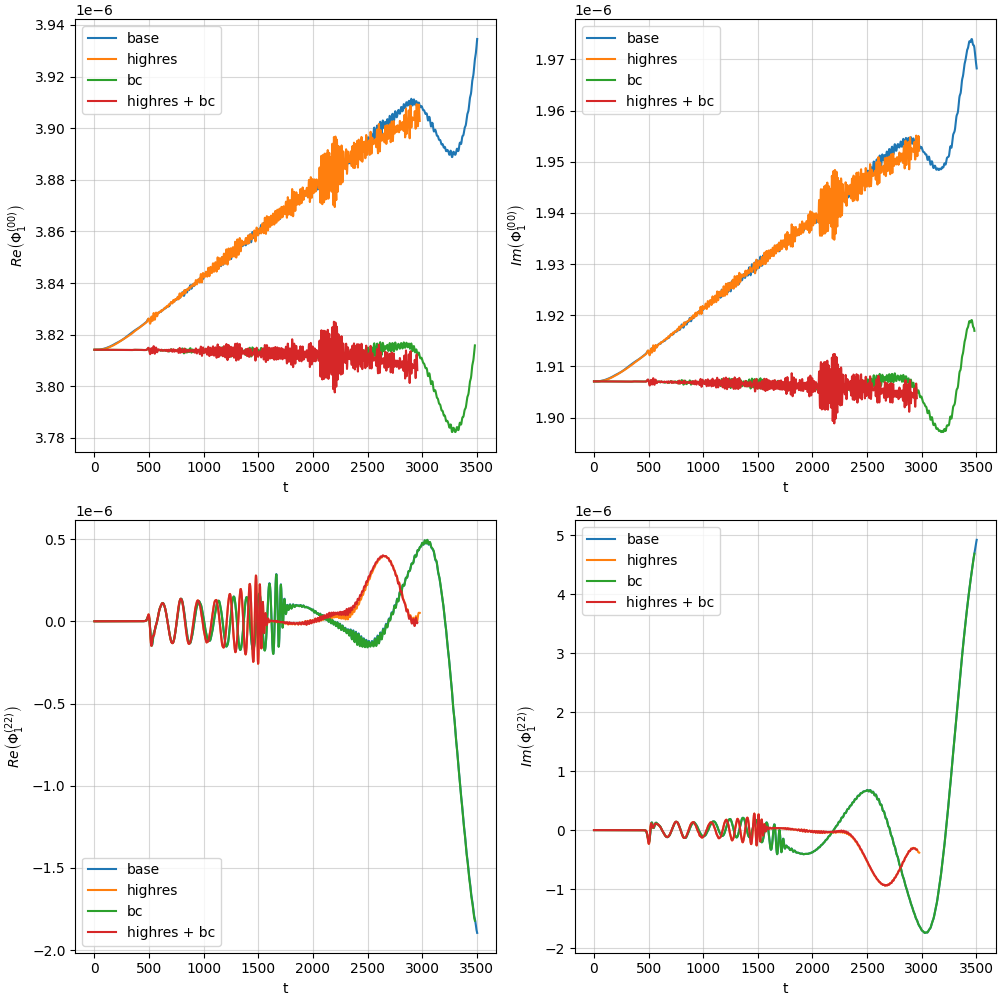

In [43]:
fig, ax = plt.subplots(2, 2, figsize=(10,10), constrained_layout=True)

R = 480

ax[0,0].plot(sd.multipoles["Phi1"][R][(0,0)].t,            sd.multipoles["Phi1"][R][(0,0)].y.real,            label="base")
ax[0,0].plot(sd_highres.multipoles["Phi1"][R][(0,0)].t,    sd_highres.multipoles["Phi1"][R][(0,0)].y.real,    label="highres")
ax[0,0].plot(sd_bc.multipoles["Phi1"][R][(0,0)].t,         sd_bc.multipoles["Phi1"][R][(0,0)].y.real,         label="bc")
ax[0,0].plot(sd_bc_highres.multipoles["Phi1"][R][(0,0)].t, sd_bc_highres.multipoles["Phi1"][R][(0,0)].y.real, label="highres + bc")

ax[0,0].grid(alpha=0.5)
ax[0,0].set_xlabel(r"t")
ax[0,0].set_ylabel(r"$Re \left( \Phi_1^{(00)}\right)$")
ax[0,0].legend();

ax[0,1].plot(sd.multipoles["Phi1"][R][(0,0)].t,            sd.multipoles["Phi1"][R][(0,0)].y.imag,            label="base")
ax[0,1].plot(sd_highres.multipoles["Phi1"][R][(0,0)].t,    sd_highres.multipoles["Phi1"][R][(0,0)].y.imag,    label="highres")
ax[0,1].plot(sd_bc.multipoles["Phi1"][R][(0,0)].t,         sd_bc.multipoles["Phi1"][R][(0,0)].y.imag,         label="bc")
ax[0,1].plot(sd_bc_highres.multipoles["Phi1"][R][(0,0)].t, sd_bc_highres.multipoles["Phi1"][R][(0,0)].y.imag, label="highres + bc")

ax[0,1].grid(alpha=0.5)
ax[0,1].set_xlabel(r"t")
ax[0,1].set_ylabel(r"$Im \left( \Phi_1^{(00)}\right)$")
ax[0,1].legend();

ax[1,0].plot(sd.multipoles["Phi1"][R][(0,0)].t,            sd.multipoles["Phi1"][R][(2,2)].y.real,            label="base")
ax[1,0].plot(sd_highres.multipoles["Phi1"][R][(2,2)].t,    sd_highres.multipoles["Phi1"][R][(2,2)].y.real,    label="highres")
ax[1,0].plot(sd_bc.multipoles["Phi1"][R][(2,2)].t,         sd_bc.multipoles["Phi1"][R][(2,2)].y.real,         label="bc")
ax[1,0].plot(sd_bc_highres.multipoles["Phi1"][R][(2,2)].t, sd_bc_highres.multipoles["Phi1"][R][(2,2)].y.real, label="highres + bc")

ax[1,0].grid(alpha=0.5)
ax[1,0].set_xlabel(r"t")
ax[1,0].set_ylabel(r"$Re \left( \Phi_1^{(22)}\right)$")
ax[1,0].legend();

ax[1,1].plot(sd.multipoles["Phi1"][R][(2,2)].t,            sd.multipoles["Phi1"][R][(2,2)].y.imag,            label="base")
ax[1,1].plot(sd_highres.multipoles["Phi1"][R][(2,2)].t,    sd_highres.multipoles["Phi1"][R][(2,2)].y.imag,    label="highres")
ax[1,1].plot(sd_bc.multipoles["Phi1"][R][(2,2)].t,         sd_bc.multipoles["Phi1"][R][(2,2)].y.imag,         label="bc")
ax[1,1].plot(sd_bc_highres.multipoles["Phi1"][R][(2,2)].t, sd_bc_highres.multipoles["Phi1"][R][(2,2)].y.imag, label="highres + bc")

ax[1,1].grid(alpha=0.5)
ax[1,1].set_xlabel(r"t")
ax[1,1].set_ylabel(r"$Im \left( \Phi_1^{(22)}\right)$")
ax[1,1].legend();

# Constraints

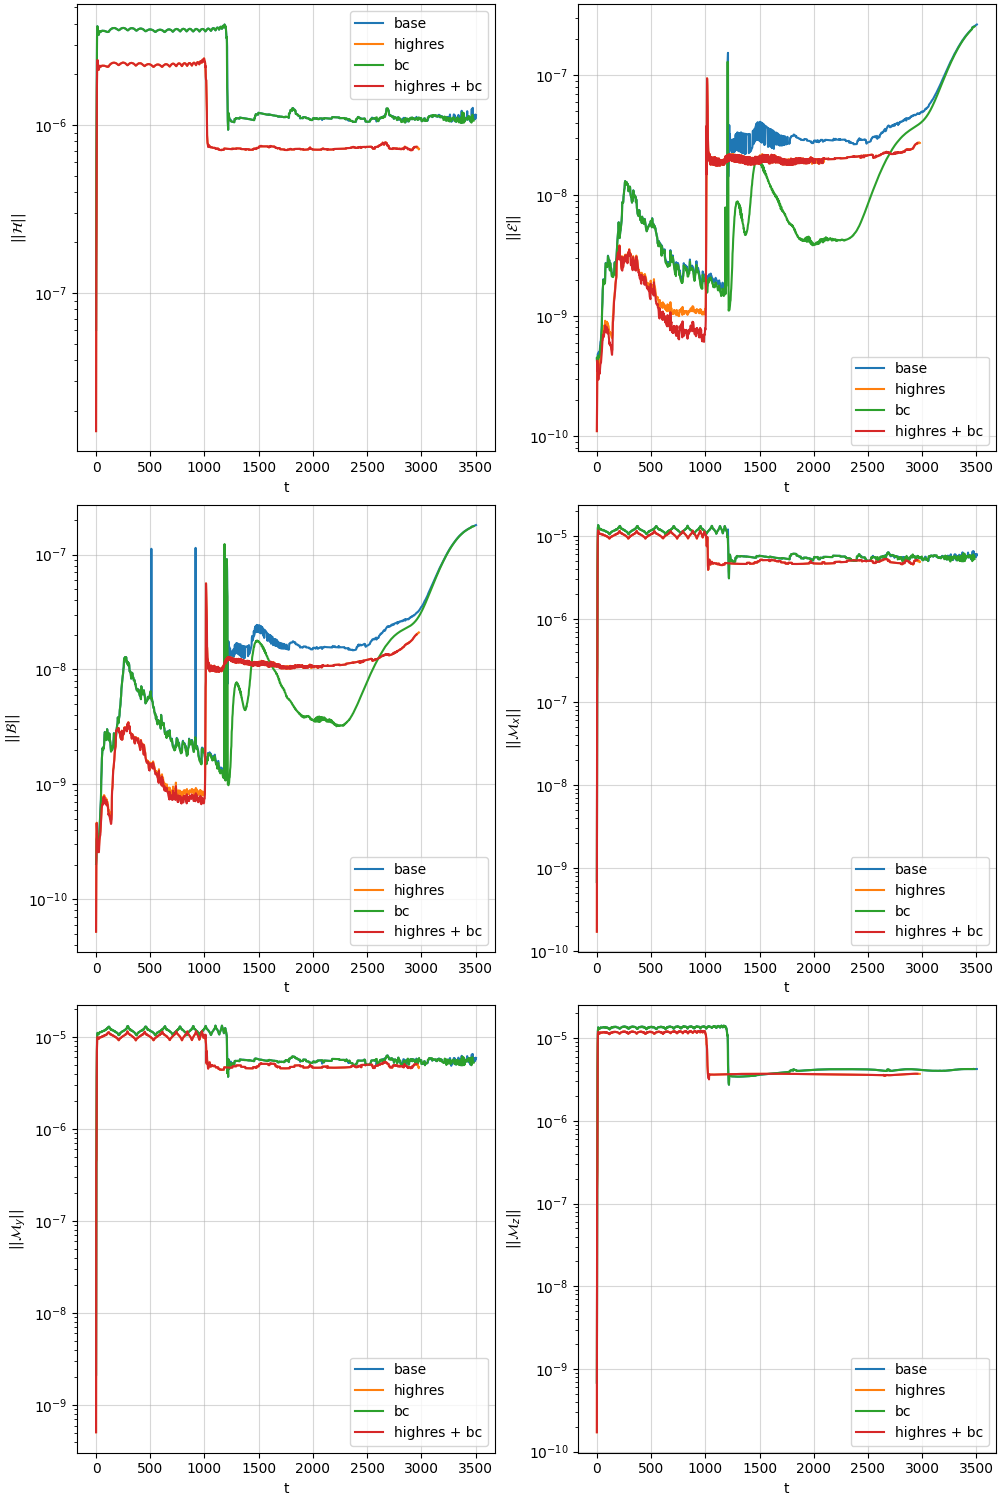

In [41]:
fig, ax = plt.subplots(3, 2, figsize=(10,15), constrained_layout=True)

ax[0,0].plot(sd.timeseries.norm2["hc"].t,            sd.timeseries.norm2["hc"].y,            label="base")
ax[0,0].plot(sd_highres.timeseries.norm2["hc"].t,    sd_highres.timeseries.norm2["hc"].y,    label="highres")
ax[0,0].plot(sd_bc.timeseries.norm2["hc"].t,         sd_bc.timeseries.norm2["hc"].y,         label="bc")
ax[0,0].plot(sd_bc_highres.timeseries.norm2["hc"].t, sd_bc_highres.timeseries.norm2["hc"].y, label="highres + bc")

ax[0,0].grid(alpha=0.5)
ax[0,0].set_xlabel("t")
ax[0,0].set_ylabel(r"$||\mathcal{H}||$")
ax[0,0].set_yscale("log")
ax[0,0].legend()

ax[0,1].plot(sd.timeseries.norm2["Ec"].t,            sd.timeseries.norm2["Ec"].y,            label="base")
ax[0,1].plot(sd_highres.timeseries.norm2["Ec"].t,    sd_highres.timeseries.norm2["Ec"].y,    label="highres")
ax[0,1].plot(sd_bc.timeseries.norm2["Ec"].t,         sd_bc.timeseries.norm2["Ec"].y,         label="bc")
ax[0,1].plot(sd_bc_highres.timeseries.norm2["Ec"].t, sd_bc_highres.timeseries.norm2["Ec"].y, label="highres + bc")

ax[0,1].grid(alpha=0.5)
ax[0,1].set_xlabel("t")
ax[0,1].set_ylabel(r"$||\mathcal{E}||$")
ax[0,1].set_yscale("log")
ax[0,1].legend()

ax[1,0].plot(sd.timeseries.norm2["Bc"].t,            sd.timeseries.norm2["Bc"].y,            label="base")
ax[1,0].plot(sd_highres.timeseries.norm2["Bc"].t,    sd_highres.timeseries.norm2["Bc"].y,    label="highres")
ax[1,0].plot(sd_bc.timeseries.norm2["Bc"].t,         sd_bc.timeseries.norm2["Bc"].y,         label="bc")
ax[1,0].plot(sd_bc_highres.timeseries.norm2["Bc"].t, sd_bc_highres.timeseries.norm2["Bc"].y, label="highres + bc")

ax[1,0].grid(alpha=0.5)
ax[1,0].set_xlabel("t")
ax[1,0].set_ylabel(r"$||\mathcal{B}||$")
ax[1,0].set_yscale("log")
ax[1,0].legend()

ax[1,1].plot(sd.timeseries.norm2["mcx"].t,            sd.timeseries.norm2["mcx"].y,            label="base")
ax[1,1].plot(sd_highres.timeseries.norm2["mcx"].t,    sd_highres.timeseries.norm2["mcx"].y,    label="highres")
ax[1,1].plot(sd_bc.timeseries.norm2["mcx"].t,         sd_bc.timeseries.norm2["mcx"].y,         label="bc")
ax[1,1].plot(sd_bc_highres.timeseries.norm2["mcx"].t, sd_bc_highres.timeseries.norm2["mcx"].y, label="highres + bc")

ax[1,1].grid(alpha=0.5)
ax[1,1].set_xlabel("t")
ax[1,1].set_ylabel(r"$||\mathcal{M}_x||$")
ax[1,1].set_yscale("log")
ax[1,1].legend()

ax[2,0].plot(sd.timeseries.norm2["mcy"].t,            sd.timeseries.norm2["mcy"].y,            label="base")
ax[2,0].plot(sd_highres.timeseries.norm2["mcy"].t,    sd_highres.timeseries.norm2["mcy"].y,    label="highres")
ax[2,0].plot(sd_bc.timeseries.norm2["mcy"].t,         sd_bc.timeseries.norm2["mcy"].y,         label="bc")
ax[2,0].plot(sd_bc_highres.timeseries.norm2["mcy"].t, sd_bc_highres.timeseries.norm2["mcy"].y, label="highres + bc")

ax[2,0].grid(alpha=0.5)
ax[2,0].set_xlabel("t")
ax[2,0].set_ylabel(r"$||\mathcal{M}_y||$")
ax[2,0].set_yscale("log")
ax[2,0].legend()

ax[2,1].plot(sd.timeseries.norm2["mcz"].t,            sd.timeseries.norm2["mcz"].y,            label="base")
ax[2,1].plot(sd_highres.timeseries.norm2["mcz"].t,    sd_highres.timeseries.norm2["mcz"].y,    label="highres")
ax[2,1].plot(sd_bc.timeseries.norm2["mcz"].t,         sd_bc.timeseries.norm2["mcz"].y,         label="bc")
ax[2,1].plot(sd_bc_highres.timeseries.norm2["mcz"].t, sd_bc_highres.timeseries.norm2["mcz"].y, label="highres + bc")

ax[2,1].grid(alpha=0.5)
ax[2,1].set_xlabel("t")
ax[2,1].set_ylabel(r"$||\mathcal{M}_z||$")
ax[2,1].set_yscale("log")
ax[2,1].legend();